<a href="https://colab.research.google.com/github/aniruddhajoshi100/DefectGAN/blob/data/condGAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
  !pip install kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"aniruddhajoshi100","key":"f9ba91827485d379d55082d7d672e0f1"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d akhatova/pcb-defects

Dataset URL: https://www.kaggle.com/datasets/akhatova/pcb-defects
License(s): unknown
 98% 1.84G/1.88G [00:16<00:01, 33.8MB/s]
100% 1.88G/1.88G [00:16<00:00, 120MB/s] 


In [ ]:
!unzip pcb-defects.zip

Archive:  pcb-defects.zip
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_01.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_02.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_03.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_04.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_05.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_06.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_07.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_08.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_09.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_10.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_11.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_12.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_13.xml  

In [ ]:
!pip install torchmetrics[image]

In [ ]:
import torchmetrics
import torch_fidelity
print(torchmetrics.__version__)
print(torch_fidelity.__version__)

1.7.4
0.3.0


In [ ]:
from torchvision.transforms import v2
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torch.nn as nn
import torch
from torch.optim import Adam
from tqdm import tqdm
import os
from torchvision.utils import save_image
import matplotlib.pyplot as plt
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore
import torchvision.utils as vutils

In [ ]:
transform = v2.Compose([v2.Resize((128,128)),
                         v2.ToTensor(),
                         v2.Normalize([0.5],[0.5])])
dataset = ImageFolder(root = "PCB_DATASET/images", transform = transform)
dataloader = DataLoader(dataset,batch_size=64,shuffle=True)

/usr/local/lib/python3.11/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


In [ ]:
class Disciminator(nn.Module):
  def __init__(self):
    super().__init__()
    self.label_conditioning_disc=nn.Sequential(
        nn.Embedding(6,100),
        nn.Linear(100,3*128*128),
        nn.LeakyReLU(0.2)
    )
    self.model=nn.Sequential(
        nn.Conv2d(6,64,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.Conv2d(64,128,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.Conv2d(128,256,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.Conv2d(256,512,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.Flatten(),
        nn.Linear(32768,1),
        nn.Sigmoid()
    )
  def forward(self,img,label):
    label_embed=self.label_conditioning_disc(label)
    label_reshape=label_embed.view(-1,3,128,128)
    concat=torch.cat((img,label_reshape),dim=1)
    output=self.model(concat)
    return output

In [ ]:
class Generator(nn.Module):
  def __init__(self):
    super().__init__()
    self.label_conditioning_gen=nn.Sequential(
        nn.Embedding(6,100)
    )
    self.latent=nn.Sequential(
        nn.Linear(200,512*4*4),
        nn.LeakyReLU(0.2)
    )
    self.model=nn.Sequential(
        nn.ConvTranspose2d(512,256,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.ConvTranspose2d(256,128,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.ConvTranspose2d(128,64,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.ConvTranspose2d(64,32,4,stride=2,padding=1),
        nn.LeakyReLU(0.2),
        nn.ConvTranspose2d(32,3,4,stride=2,padding=1),
        nn.Tanh()
    )
  def forward(self,z,label):
    label_embed=self.label_conditioning_gen(label)
    concat=torch.cat((z,label_embed),dim=1)
    latent=self.latent(concat)
    reshape=latent.view(-1,512,4,4)
    img=self.model(reshape)
    return img

In [ ]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
discriminator=Disciminator().to(device)
generator=Generator().to(device)

In [ ]:
loss=nn.BCELoss()
optimizer_G = Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [ ]:

# --- Hyperparameters ---
epochs = 50
lr = 0.0002
beta1 = 0.5
batch_size = 64
z_dim = 100
n_classes = 6
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Assuming elsewhere you defined these correctly ---
# generator, discriminator = your models
# dataloader = your dataloader
# loss = your BCELoss
# optimizer_G, optimizer_D = Adam optimizers


# --- Metrics & Visualization Setup ---
os.makedirs("generated_images", exist_ok=True)
fid = FrechetInceptionDistance(feature=2048).to(device)
inception_score = InceptionScore().to(device)

# Fixed noise for generating images
fixed_noise = torch.randn(64, z_dim, device=device)
fixed_labels = torch.randint(0, n_classes, (64,), device=device)


# --- Training Loop ---
print("Starting Training Loop...")
for epoch in range(epochs):
    loop = tqdm(dataloader, leave=True)
    fid.reset()
    inception_score.reset()

    for i, (real_imgs, labels) in enumerate(loop):
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)
        labels = labels.to(device)

        # --- Train Discriminator ---
        optimizer_D.zero_grad()
        noise = torch.randn(batch_size, z_dim, device=device)
        fake_imgs = generator(noise, labels)

        real_target = torch.ones(batch_size, 1, device=device)
        fake_target = torch.zeros(batch_size, 1, device=device)

        d_loss_real = loss(discriminator(real_imgs, labels), real_target)
        d_loss_fake = loss(discriminator(fake_imgs.detach(), labels), fake_target)
        d_loss = (d_loss_real + d_loss_fake) / 2

        d_loss.backward()
        optimizer_D.step()

        # --- Train Generator ---
        optimizer_G.zero_grad()
        generated_imgs = generator(noise, labels)
        g_output = discriminator(generated_imgs, labels)
        g_loss = loss(g_output, real_target)

        g_loss.backward()
        optimizer_G.step()

        # --- Update Progress Bar ---
        loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
        loop.set_postfix(D_Loss=d_loss.item(), G_Loss=g_loss.item())

        # --- Metrics (FID, IS) ---
        real_imgs_uint8 = ((real_imgs.detach() + 1) / 2 * 255).to(torch.uint8).to(device)
        fake_imgs_uint8 = ((generated_imgs.detach() + 1) / 2 * 255).to(torch.uint8).to(device)

        if real_imgs_uint8.shape[1] == 1:
            real_imgs_uint8 = real_imgs_uint8.repeat(1, 3, 1, 1)
            fake_imgs_uint8 = fake_imgs_uint8.repeat(1, 3, 1, 1)

        fid.update(real_imgs_uint8, real=True)
        fid.update(fake_imgs_uint8, real=False)
        inception_score.update(fake_imgs_uint8)


    # --- Epoch-wise Logging ---
    epoch_fid = fid.compute()
    mean_is, std_is = inception_score.compute()
    print(f"\nEpoch {epoch+1}/{epochs} Summary | FID: {epoch_fid:.4f} | IS: {mean_is:.4f} (std: {std_is:.4f})")

    # --- Save images every 5 epochs ---
    if (epoch + 1) % 5 == 0:
        generator.eval()
        with torch.no_grad():
            fixed_fake_imgs = generator(fixed_noise, fixed_labels).detach().cpu()
        vutils.save_image(fixed_fake_imgs, f"generated_images/epoch_{epoch+1}.png", normalize=True, nrow=8)
        generator.train()

print("Training finished.")


Starting Training Loop...


Epoch [1/50]: 100%|██████████| 11/11 [01:02<00:00,  5.66s/it, D_Loss=0.0717, G_Loss=3.81]



Epoch 1/50 Summary | FID: 282.2370 | IS: 1.2592 (std: 0.0295)


Epoch [2/50]: 100%|██████████| 11/11 [01:01<00:00,  5.64s/it, D_Loss=0.415, G_Loss=1.82]



Epoch 2/50 Summary | FID: 309.6460 | IS: 1.4627 (std: 0.0339)


Epoch [3/50]: 100%|██████████| 11/11 [01:02<00:00,  5.68s/it, D_Loss=0.72, G_Loss=1.71]


... (91 outputs left out)

Epoch [49/50]: 100%|██████████| 11/11 [01:01<00:00,  5.60s/it, D_Loss=0.353, G_Loss=2.25]



Epoch 49/50 Summary | FID: 263.5841 | IS: 1.2784 (std: 0.0489)


Epoch [50/50]: 100%|██████████| 11/11 [01:01<00:00,  5.59s/it, D_Loss=0.885, G_Loss=4.68]



Epoch 50/50 Summary | FID: 230.9709 | IS: 1.1797 (std: 0.0091)
Training finished.


In [ ]:
import matplotlib.pyplot as plt

epochs = list(range(1, 51))

# Manually extracted values from your logs:
fid_scores = [
    282.23, 309.64, 291.40, 275.02, 276.74,
    266.48, 270.26, 288.47, 326.01, 290.01,
    257.59, 255.10, 274.32, 261.20, 287.13,
    285.20, 299.56, 317.28, 243.59, 272.69,
    292.02, 353.20, 272.66, 304.62, 270.91,
    275.36, 262.28, 283.64, 292.77, 273.68,
    307.20, 339.55, 246.53, 277.87, 244.52,
    227.48, 268.49, 238.06, 243.65, 256.17,
    252.04, 282.73, 235.10, 247.20, 247.08,
    210.36, 248.07, 230.23, 263.58, 230.97
]

is_scores = [
    1.259, 1.462, 1.349, 1.338, 1.245,
    1.199, 1.184, 1.335, 1.254, 1.553,
    1.431, 1.316, 1.712, 1.199, 1.276,
    1.285, 1.531, 1.150, 1.237, 1.157,
    1.490, 1.025, 1.140, 1.212, 1.236,
    1.415, 1.460, 1.177, 1.396, 1.236,
    1.150, 1.318, 1.423, 1.386, 1.392,
    1.341, 1.133, 1.271, 1.576, 1.244,
    1.416, 1.219, 1.197, 1.242, 1.207,
    1.330, 1.336, 1.259, 1.278, 1.179
]


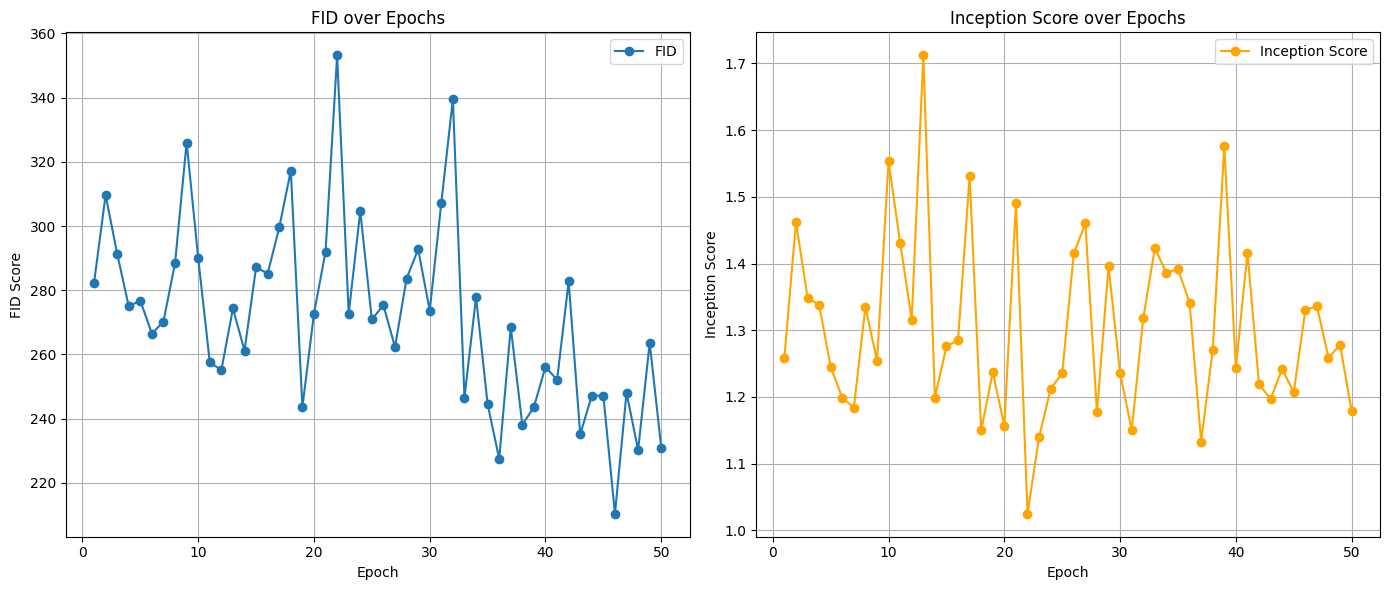

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(epochs, fid_scores, marker='o', label='FID')
plt.xlabel('Epoch')
plt.ylabel('FID Score')
plt.title('FID over Epochs')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, is_scores, marker='o', color='orange', label='Inception Score')
plt.xlabel('Epoch')
plt.ylabel('Inception Score')
plt.title('Inception Score over Epochs')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


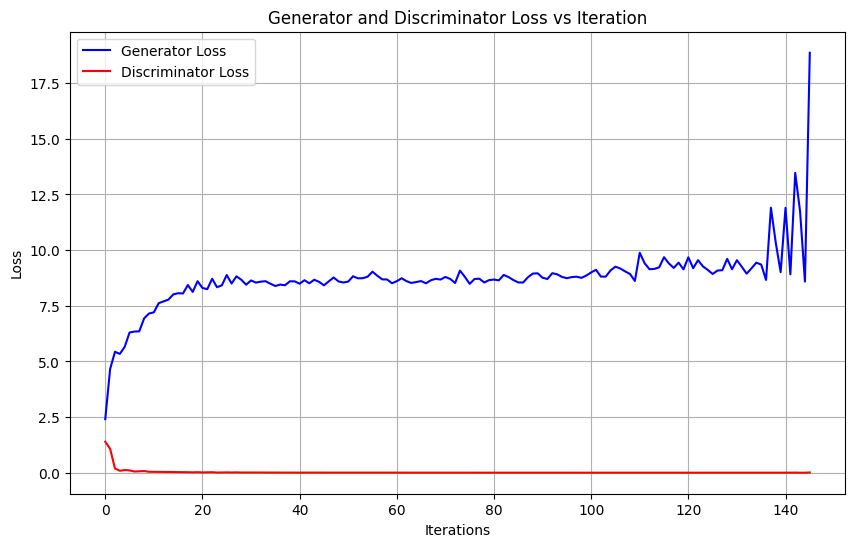

In [ ]:
import matplotlib.pyplot as plt

g_loss = [
    2.4088, 4.6564, 5.4330, 5.3392, 5.6536, 6.2973, 6.3421, 6.3516,
    6.9338, 7.1507, 7.2048, 7.6165, 7.6942, 7.7765, 8.0104, 8.0641,
    8.0532, 8.4308, 8.1226, 8.6031, 8.3006, 8.2470, 8.7118, 8.3331,
    8.4188, 8.8796, 8.4991, 8.8200, 8.6691, 8.4471, 8.6380, 8.5412,
    8.5829, 8.6037, 8.4892, 8.3882, 8.4513, 8.4214, 8.6002, 8.5959,
    8.4914, 8.6487, 8.5092, 8.6693, 8.5748, 8.4186, 8.5953, 8.7711,
    8.5950, 8.5459, 8.5854, 8.8254, 8.7326, 8.7391, 8.8068, 9.0312,
    8.8475, 8.6864, 8.6811, 8.5117, 8.6036, 8.7359, 8.6053, 8.5240,
    8.5681, 8.6089, 8.5097, 8.6448, 8.7108, 8.6782, 8.7944, 8.7037,
    8.5240, 9.0786, 8.8040, 8.4844, 8.7038, 8.7144, 8.5456, 8.6526,
    8.6775, 8.6405, 8.8839, 8.7889, 8.6550, 8.5484, 8.5434, 8.7841,
    8.9454, 8.9583, 8.7584, 8.7042, 8.9627, 8.9132, 8.7957, 8.7387,
    8.7876, 8.8054, 8.7543, 8.8554, 8.9988, 9.1160, 8.8113, 8.8083,
    9.0877, 9.2580, 9.1729, 9.0437, 8.9279, 8.6145, 9.8814, 9.4126,
    9.1409, 9.1568, 9.2253, 9.6812, 9.4010, 9.1992, 9.4371, 9.1371,
    9.6766, 9.1883, 9.5493, 9.2699, 9.1108, 8.9291, 9.0817, 9.0981,
    9.6080, 9.1394, 9.5468, 9.2543, 8.9425, 9.1824, 9.4367, 9.3502,
    8.6599, 11.9053, 10.3253, 9.0104, 11.8976, 8.9143, 13.4704, 11.7357,
    8.5887, 18.8648
]

d_loss = [
    1.3959, 1.0772, 0.1928, 0.0900, 0.1234, 0.1071, 0.0559, 0.0676,
    0.0761, 0.0445, 0.0424, 0.0442, 0.0340, 0.0321, 0.0334, 0.0270,
    0.0260, 0.0254, 0.0191, 0.0269, 0.0159, 0.0212, 0.0248, 0.0106,
    0.0157, 0.0176, 0.0130, 0.0175, 0.0114, 0.0104, 0.0135, 0.0101,
    0.0114, 0.0122, 0.0094, 0.0083, 0.0094, 0.0085, 0.0087, 0.0076,
    0.0070, 0.0079, 0.0066, 0.0077, 0.0086, 0.0060, 0.0065, 0.0075,
    0.0051, 0.0071, 0.0072, 0.0067, 0.0059, 0.0060, 0.0062, 0.0067,
    0.0055, 0.0067, 0.0064, 0.0054, 0.0058, 0.0054, 0.0054, 0.0063,
    0.0048, 0.0042, 0.0046, 0.0046, 0.0056, 0.0047, 0.0046, 0.0040,
    0.0040, 0.0062, 0.0038, 0.0045, 0.0045, 0.0031, 0.0034, 0.0040,
    0.0039, 0.0040, 0.0044, 0.0045, 0.0038, 0.0033, 0.0033, 0.0035,
    0.0059, 0.0030, 0.0027, 0.0031, 0.0043, 0.0031, 0.0038, 0.0033,
    0.0031, 0.0032, 0.0033, 0.0032, 0.0037, 0.0034, 0.0038, 0.0030,
    0.0039, 0.0033, 0.0037, 0.0036, 0.0028, 0.0056, 0.0049, 0.0029,
    0.0023, 0.0036, 0.0033, 0.0049, 0.0036, 0.0042, 0.0041, 0.0022,
    0.0044, 0.0047, 0.0041, 0.0034, 0.0027, 0.0031, 0.0032, 0.0060,
    0.0034, 0.0032, 0.0038, 0.0029, 0.0027, 0.0039, 0.0045, 0.0045,
    0.0048, 0.0061, 0.0030, 0.0021, 0.0057, 0.0050, 0.0077, 0.0025,
    0.0023, 0.0136
]

plt.figure(figsize=(10, 6))
plt.plot(g_loss, label='Generator Loss', color='blue')
plt.plot(d_loss, label='Discriminator Loss', color='red')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.title('Generator and Discriminator Loss vs Iteration')
plt.legend()
plt.grid(True)
plt.show()
